In [ ]:
import sys
sys.path.append("..")
from data_reader import DataReader
data_reader = DataReader()
raw, channels, events = data_reader.read_data(
    subject="102",
    duration=60.0,
)

from preprocess import Preprocessor

preprocessor = Preprocessor(raw)
preprocessor.run_pipeline()

events_arr = preprocessor.events_arr
event_dict = preprocessor.event_dict

None
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 6601 samples (6.601 s)

Successfully filtered the data.
Fitting ICA to data using 64 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 62.9s.
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
  

/tmp/ipykernel_65174/748382188.py:2: RuntimeWarning: More events than default colors available. You should pass a list of unique colors.
  fig = mne.viz.plot_events(


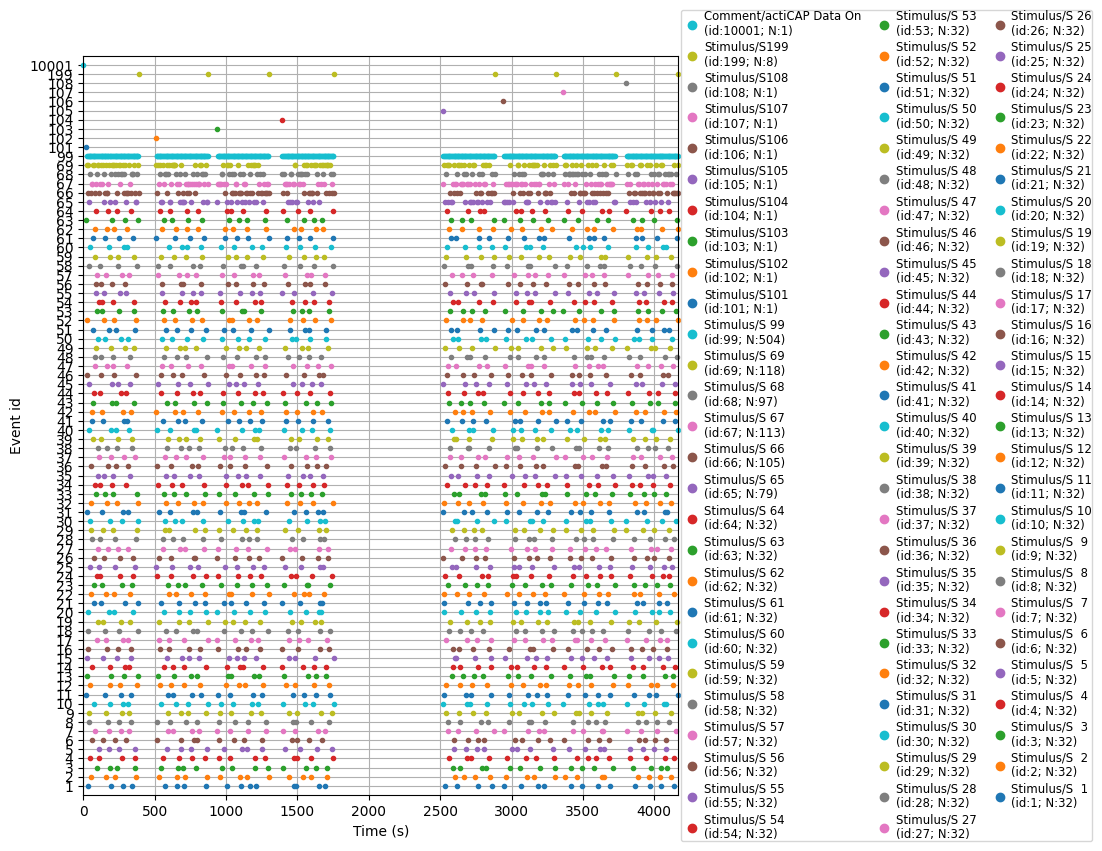

In [2]:
import mne
fig = mne.viz.plot_events(
    events_arr, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp
)

In [3]:
import numpy as np

epochs_train, epochs_test= preprocessor.split_train_test()

X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())

print(X_train.shape, X_test.shape) 

(1638, 64, 250) (410, 64, 250)


In [4]:
B_train = preprocessor.make_B(epochs_train)    # (1638, 250)
B_test  = preprocessor.make_B(epochs_test)     # (410, 250)
print(B_test.shape)
print(B_train.shape)

(410, 250)
(1638, 250)


In [5]:
import tensorflow as tf
from functions import BunDLeNet, BunDLeTrainer

model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)
all_losses=[]

labels_train = preprocessor.create_labels_for_epochs(epochs_train)    # Form (1638, 250)
labels_test = preprocessor.create_labels_for_epochs(epochs_test)      # Form (410, 250)

number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")

random_generator = np.random.default_rng(11)
shuffled_order = random_generator.permutation(len(epoch_numbers))

for batch_start in range(0, len(shuffled_order), preprocessor.BATCH_SIZE):
    selected_pairs = shuffled_order[batch_start : batch_start + preprocessor.BATCH_SIZE]

    window_pairs, target_labels = preprocessor.build_training_batch(
        X_train,
        labels_train,
        epoch_numbers[selected_pairs],
        start_time_points[selected_pairs],
        preprocessor.WINDOW_LENGTH,
    )

    markov_loss, behaviour_loss, total_loss = trainer.train_step(
        tf.convert_to_tensor(window_pairs, dtype=tf.float32),
        tf.convert_to_tensor(target_labels, dtype=tf.int64),
        gamma=preprocessor.GAMMA,
    )
    all_losses.append([float(markov_loss), float(behaviour_loss), float(total_loss)])


I0000 00:00:1794259483.282272   65174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794259483.500769   65174 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794259484.742622   65174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


None


W0000 00:00:1794259485.499632   65174 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1794259485.502434   65174 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794259485.612438   65174 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:03:00.0, compute capability: 12.0a


X_train shape: (1638, 64, 250)
Number of epochs: 1638
Number of channels: 64


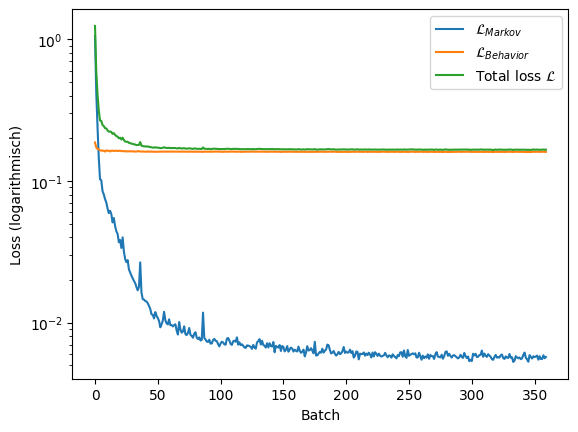

In [6]:
import matplotlib.pyplot as plt
loss_history = np.array(all_losses)      # Form (Anzahl Batches, 3)

loss_names = [
    r"$\mathcal{L}_{Markov}$",
    r"$\mathcal{L}_{Behavior}$",
    r"Total loss $\mathcal{L}$",
]

plt.figure()
for column_number, loss_name in enumerate(loss_names):
    plt.semilogy(loss_history[:, column_number], label=loss_name)
plt.xlabel("Batch")
plt.ylabel("Loss (logarithmisch)")
plt.legend()
plt.show()